<a href="https://colab.research.google.com/github/dillfigueira804-boop/Ciberseguranca-/blob/main/detector_fraudes_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:

import pandas as pd
from sklearn.tree import DecisionTreeClassifier

# 1. Histórico enviado pelo gerente Carlos (Belém/Ananindeua)
dados = {
    'valor': list((
50, 120, 4500, 3200, 80, 5100, 200, 2900, 35, 4100)),
    'hora': list((
14, 10, 2, 3, 18, 1, 12, 4, 9, 23)),
    'fraude':
list((
0, 0, 1, 1, 0, 1, 0, 1, 0, 1)),
}
df = pd.DataFrame(dados)

# 2. Separando o que a IA analisa (X) do que ela precisa prever (y)
X = df[['valor', 'hora']]
y = df['fraude']

# 3. Criando e treinando a Árvore de Decisão
modelo = DecisionTreeClassifier(random_state=42)
modelo.fit(X, y)

print('Modelo treinado com sucesso!')

Modelo treinado com sucesso!


In [9]:

# 1. As 3 compras enviadas pelo gerente Carlos na fila de análise
novas_compras = pd.DataFrame({
    'valor': list((45, 3800, 250)),
    'hora': list((14, 3, 19)),
})

# 2. A IA faz a previsão na hora (0 = Aprovar | 1 = Bloquear/Fraude)
previsoes = modelo.predict(novas_compras)

# 3. Mostrando o resultado de forma clara para o relatório
novas_compras['resultado_ia'] = previsoes
print(novas_compras)

   valor  hora  resultado_ia
0     45    14             0
1   3800     3             1
2    250    19             0


--- TESTE DE ESTRESSE ---
   valor  hora  previsao_ia
0   3500    14            1
1    150     3            0


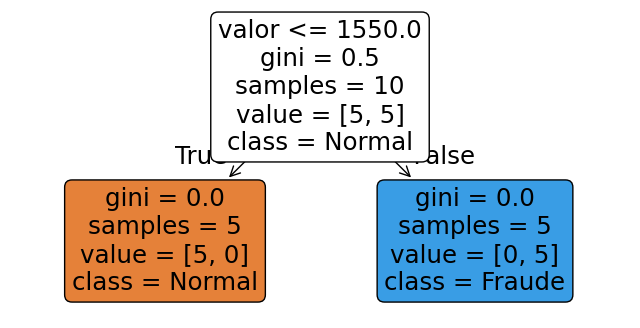

In [10]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Teste de Estresse (Cenários ambíguos do Carlos)
teste_dificil = pd.DataFrame({
    'valor': list((3500, 150)),
    'hora': list((14, 3)),
})
teste_dificil['previsao_ia'] = modelo.predict(teste_dificil)
print('--- TESTE DE ESTRESSE ---')
print(teste_dificil)

# 2. Abrindo a "mente" da IA (Desenhando a Árvore de Decisão)
plt.figure(figsize=(8, 4))
plot_tree(
    modelo,
    feature_names=['valor', 'hora'],
    class_names=['Normal', 'Fraude'],
    filled=True,
    rounded=True,
)
plt.show()

--- NOVO TESTE DE ESTRESSE (V2) ---
   valor  hora  previsao_ia  previsao_v2
0   3500    14            1            0
1    150     3            0            1


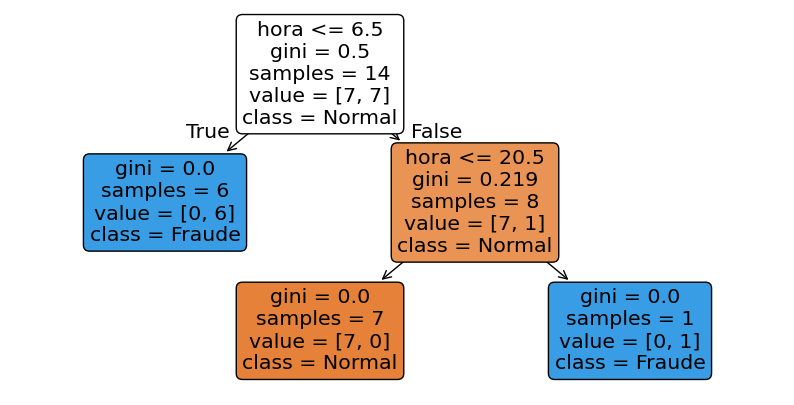

In [11]:

# 1. Histórico mais realista (agora com compras altas de dia e baixas de madrugada)
dados_v2 = {
    'valor': list(
        (50, 120, 4500, 3200, 80, 5100, 200, 2900, 35, 4100, 3800, 4200, 120, 90)
    ),
    'hora': list((14, 10, 2, 3, 18, 1, 12, 4, 9, 23, 15, 11, 2, 4)),
    'fraude': list((0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1)),
}

df_v2 = pd.DataFrame(dados_v2)

# 2. Treinando a Versão 2 da IA
modelo_v2 = DecisionTreeClassifier(random_state=42)
modelo_v2.fit(df_v2[['valor', 'hora']], df_v2['fraude'])

# 3. Refazendo o Teste de Estresse do Carlos!
teste_dificil['previsao_v2'] = modelo_v2.predict(
    teste_dificil[['valor', 'hora']]
)
print('--- NOVO TESTE DE ESTRESSE (V2) ---')
print(teste_dificil)

# 4. Desenhando a nova mente da IA (agora ela precisa olhar a HORA!)
plt.figure(figsize=(10, 5))
plot_tree(
    modelo_v2,
    feature_names=['valor', 'hora'],
    class_names=['Normal', 'Fraude'],
    filled=True,
    rounded=True,
)
plt.show()